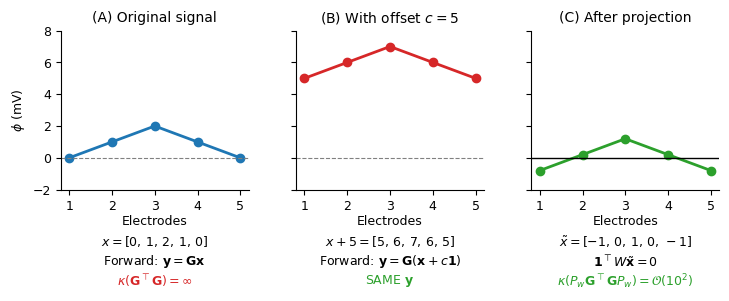

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# --- Estilo compacto para figura de 2 columnas ---
plt.rcParams.update({
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
})

fig, axes = plt.subplots(1, 3, figsize=(8.5, 3.0), sharey=True)

# Datos toy
x = np.array([0, 1, 2, 1, 0], dtype=float)
electrodes = np.arange(1, len(x) + 1)
c = 5.0

def add_bottom_notes(ax, lines, colors=None, y0=-0.28, dy=0.12):
    """
    Coloca textos debajo del xlabel usando coordenadas del eje.
    y0 y dy controlan qué tan abajo quedan.
    """
    if colors is None:
        colors = [None] * len(lines)

    for i, (txt, col) in enumerate(zip(lines, colors)):
        ax.text(
            0.5, y0 - i * dy, txt,
            transform=ax.transAxes,
            ha='center', va='top',
            color=col if col else 'black'
        )

# ---------------- Panel A: Original ----------------
axes[0].plot(electrodes, x, 'o-', color='tab:blue', linewidth=2, markersize=6)
axes[0].axhline(0, color='gray', linestyle='--', linewidth=0.8)
axes[0].set_ylim(-2, 8)
axes[0].set_xticks(electrodes)
axes[0].set_xlabel('Electrodes', labelpad=2)
axes[0].set_ylabel(r'$\phi$ (mV)')
axes[0].set_title('(A) Original signal')

add_bottom_notes(
    axes[0],
    [r'$x=[0,\,1,\,2,\,1,\,0]$',
     r'Forward: $\mathbf{y}=\mathbf{Gx}$',
     r'$\kappa(\mathbf{G}^\top\mathbf{G})=\infty$'],
    colors=[None, None, 'tab:red']
)

# ---------------- Panel B: With offset ----------------
x_offset = x + c
axes[1].plot(electrodes, x_offset, 'o-', color='tab:red', linewidth=2, markersize=6)
axes[1].axhline(0, color='gray', linestyle='--', linewidth=0.8)
axes[1].set_ylim(-2, 8)
axes[1].set_xticks(electrodes)
axes[1].set_xlabel('Electrodes', labelpad=2)
axes[1].set_title(rf'(B) With offset $c={int(c)}$')

add_bottom_notes(
    axes[1],
    [r'$x+5=[5,\,6,\,7,\,6,\,5]$',
     r'Forward: $\mathbf{y}=\mathbf{G}(\mathbf{x}+c\mathbf{1})$',
     r'SAME $\mathbf{y}$'],
    colors=[None, None, 'tab:green']
)

# ---------------- Panel C: After projection ----------------
x_proj = x - np.mean(x)
axes[2].plot(electrodes, x_proj, 'o-', color='tab:green', linewidth=2, markersize=6)
axes[2].axhline(0, color='black', linestyle='-', linewidth=1.0)
axes[2].set_ylim(-2, 8)
axes[2].set_xticks(electrodes)
axes[2].set_xlabel('Electrodes', labelpad=2)
axes[2].set_title('(C) After projection')

add_bottom_notes(
    axes[2],
    [r'$\tilde{x}=[-1,\,0,\,1,\,0,\,-1]$',
     r'$\mathbf{1}^\top W\tilde{\mathbf{x}}=0$',
     r'$\kappa(P_w\mathbf{G}^\top\mathbf{G}P_w)=\mathcal{O}(10^2)$'],
    colors=[None, None, 'tab:green']
)

# Limpieza visual
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# En vez de tight_layout, ajusta margen inferior manualmente
fig.subplots_adjust(bottom=0.35, wspace=0.25)

fig.savefig('fig_gauge_schematic.pdf', bbox_inches='tight', dpi=300)
plt.show()


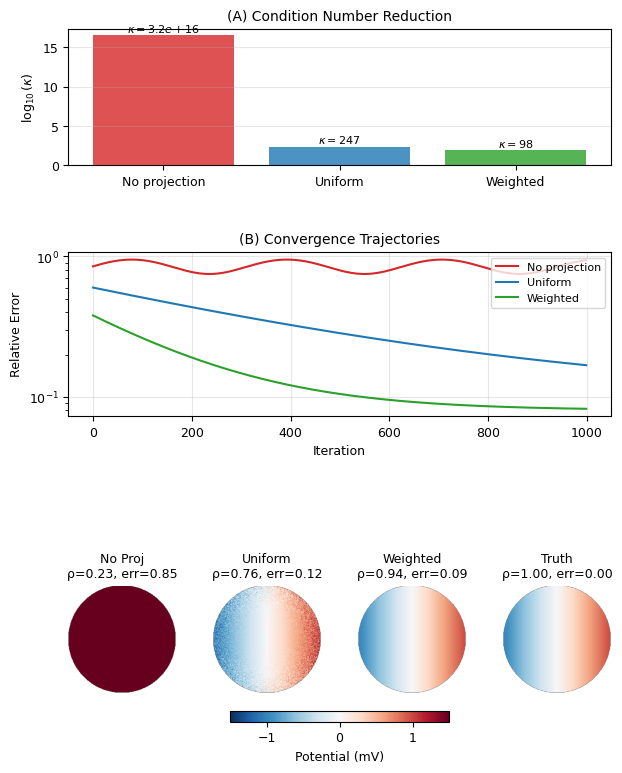

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

# --- Estilo consistente con figura de appendix ---
plt.rcParams.update({
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
})

fig = plt.figure(figsize=(7.0, 9.0))
gs = GridSpec(
    nrows=3, ncols=4, figure=fig,
    height_ratios=[1.0, 1.2, 1.6],
    hspace=0.5, wspace=0.35
)

# ---------------- Panel A: Condition numbers (fila 1 completa) ----------------
ax1 = fig.add_subplot(gs[0, :])

kappas = np.array([3.2e16, 247.0, 98.0], dtype=float)
labels = ['No projection', 'Uniform', 'Weighted']
colors = ['tab:red', 'tab:blue', 'tab:green']

bars = ax1.bar(labels, np.log10(kappas), color=colors, alpha=0.8)
ax1.set_ylabel(r'$\log_{10}(\kappa)$')
ax1.set_title('(A) Condition Number Reduction')
ax1.grid(axis='y', alpha=0.3)

for bar, kappa in zip(bars, kappas):
    txt = rf'$\kappa={kappa:.1e}$' if kappa >= 1e4 else rf'$\kappa={kappa:.0f}$'
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        txt,
        ha='center', va='bottom', fontsize=8
    )

# ---------------- Panel B: Convergence (fila 2 completa) ----------------
ax2 = fig.add_subplot(gs[1, :])

iters = np.arange(1000)

# Curvas sintéticas para ilustración (puedes reemplazar por datos reales)
err_none = 0.85 + 0.1 * np.sin(iters / 50.0)              # oscilante
err_uniform = 0.5 * np.exp(-iters / 500.0) + 0.10         # lenta
err_weighted = 0.3 * np.exp(-iters / 200.0) + 0.08        # rápida

ax2.semilogy(iters, err_none, color=colors[0], label='No projection', linewidth=1.5)
ax2.semilogy(iters, err_uniform, color=colors[1], label='Uniform', linewidth=1.5)
ax2.semilogy(iters, err_weighted, color=colors[2], label='Weighted', linewidth=1.5)

ax2.set_xlabel('Iteration')
ax2.set_ylabel('Relative Error')
ax2.set_title('(B) Convergence Trajectories')
ax2.legend(loc='upper right', fontsize=8)
ax2.grid(alpha=0.3)

# ---------------- Panel C: 4 mapas (fila 3, 4 columnas) ----------------
axes_maps = [fig.add_subplot(gs[2, i]) for i in range(4)]
titles = ['No Proj', 'Uniform', 'Weighted', 'Truth']
rhos = [0.23, 0.76, 0.94, 1.00]
errs = [0.85, 0.12, 0.09, 0.00]

# Campo 2D tipo proyección ortográfica en disco
res = 220
u = np.linspace(-1, 1, res)
v = np.linspace(-1, 1, res)
U, V = np.meshgrid(u, v)
R = np.sqrt(U**2 + V**2)
mask = R <= 1.0

# Patrón "verdad" simple y estable
Z = np.zeros_like(U)
Z[mask] = U[mask]  # gradiente suave lateral

V_truth = Z
V_none = Z + 5.0   # sesgo DC
edge_noise = np.random.randn(*U.shape) * (R**3)           # ruido crece hacia borde
V_uniform = Z + 0.30 * edge_noise
V_weighted = Z

fields = [V_none, V_uniform, V_weighted, V_truth]

vmin, vmax = -1.5, 1.5
im = None

for ax, field, title, rho, err in zip(axes_maps, fields, titles, rhos, errs):
    data = np.ma.array(field, mask=~mask)
    im = ax.imshow(
        data, origin='lower', extent=[-1, 1, -1, 1],
        vmin=vmin, vmax=vmax, cmap='RdBu_r'
    )
    ax.set_aspect('equal')
    ax.set_title(f'{title}\nρ={rho:.2f}, err={err:.2f}', fontsize=9)
    ax.axis('off')

# Colorbar compartida
cbar = fig.colorbar(im, ax=axes_maps, orientation='horizontal', fraction=0.05, pad=0.08)
cbar.set_label('Potential (mV)')

fig.savefig('fig_gauge_experiment.pdf', bbox_inches='tight')
plt.show()


Meshes
Electrodes
    60x3
Heart
 Node: 502x3
 Face: 1000x3

Torso : 2002x3
        4000x3
        
60x167

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Data from the table
# -----------------------------
noise_levels = ["Clean", "25 dB", "20 dB", "15 dB"]
x = np.arange(len(noise_levels))

data = {
    "Auckland": {
        "RMSE": [0.083, 0.095, 0.102, 0.124],
        "PCC":  [0.993, 0.977, 0.966, 0.941],
        "SC":   [0.990, 0.983, 0.975, 0.961],
    },
    "Bordeaux": {
        "RMSE": [0.234, 0.274, 0.295, 0.367],
        "PCC":  [0.954, 0.935, 0.923, 0.893],
        "SC":   [0.989, 0.951, 0.942, 0.925],
    },
    "Utah2002": {
        "RMSE": [0.120, 0.140, 0.150, 0.185],
        "PCC":  [0.986, 0.968, 0.956, 0.928],
        "SC":   [0.994, 0.986, 0.978, 0.961],
    },
}

# -----------------------------
# Global style for paper-ready plots
# -----------------------------
plt.rcParams.update({
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "legend.fontsize": 8,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "pdf.fonttype": 42,   # better text embedding
    "ps.fonttype": 42,
})

def plot_metric(metric_name, y_label, filename_pdf):
    fig = plt.figure(figsize=(4.6, 3.2))  # compact single-column friendly

    markers = ["o", "s", "D"]
    for (i, (ds, ds_dict)) in enumerate(data.items()):
        y = ds_dict[metric_name]
        plt.plot(x, y, marker=markers[i], linewidth=1.8, label=ds)

    plt.xticks(x, noise_levels)
    plt.xlabel("Noise level (SNR)")
    plt.ylabel(y_label)
    plt.grid(True, alpha=0.25)
    plt.legend(frameon=False, loc="best")
    plt.tight_layout()

    plt.savefig(filename_pdf, bbox_inches="tight")
    plt.savefig(filename_pdf.replace(".pdf", ".png"), dpi=300, bbox_inches="tight")
    plt.close(fig)

# -----------------------------
# Generate three separate figures
# -----------------------------
plot_metric("RMSE", "RMSE (mV)", "fig_noise_rmse_3levels.pdf")
plot_metric("PCC",  "PCC",       "fig_noise_pcc_3levels.pdf")
plot_metric("SC",   "SC",        "SC",        "fig_noise_sc_3levels.pdf")

print("Saved:")
print(" - fig_noise_rmse_3levels.pdf/.png")
print(" - fig_noise_pcc_3levels.pdf/.png")
print(" - fig_noise_sc_3levels.pdf/.png")


TypeError: plot_metric() takes 3 positional arguments but 4 were given